<a href="https://colab.research.google.com/github/fabricejumel/5ETI_5IRC_20262027-DEEPLEARNING/blob/main/detection_CPE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TensorFlow Hub Object Detection (Version Moderne & Corrigée)

Ce notebook reprend l'approche originale TensorFlow Hub pour faire tester des détecteurs d'objets aux élèves, sans les erreurs de compilation bloquantes sur les environnements Colab récents.

In [1]:
# 1. Installation des bonnes versions compatibles pour éviter les conflits Protobuf / Numpy
!pip install -q "numpy>=1.26.0" "protobuf>=5.29.1" tensorflow-hub tf-models-official

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf-tf 2.21.0 requires tensorflow==2.21.0, but you have tensorflow 2.20.0 which is incompatible.


In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import tensorflow as tf
import tensorflow_hub as hub
from six.moves.urllib.request import urlopen
from io import BytesIO

print("Version de TensorFlow :", tf.__version__)

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Version de TensorFlow : 2.20.0


In [8]:
# Fonction utilitaire pour charger l'image avec un User-Agent pour éviter l'erreur 403
from urllib.request import Request

def load_image_into_numpy_array(path):
    if path.startswith('http'):
        # Ajout d'un User-Agent pour éviter le blocage HTTP 403 de certains serveurs (comme Wikimedia)
        req = Request(path, headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'})
        response = urlopen(req)
        image_data = response.read()
        image = Image.open(BytesIO(image_data))
    else:
        image = Image.open(path)

    im_width, im_height = image.size
    return np.array(image.getdata()).reshape((1, im_height, im_width, 3)).astype(np.uint8)

# Modèle léger et rapide idéal pour les TPs (SSD MobileNet v2)
module_handle = "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"

print("Chargement du modèle TensorFlow Hub...")
detector = hub.load(module_handle)
print("Modèle chargé avec succès !")

Chargement du modèle TensorFlow Hub...
Modèle chargé avec succès !


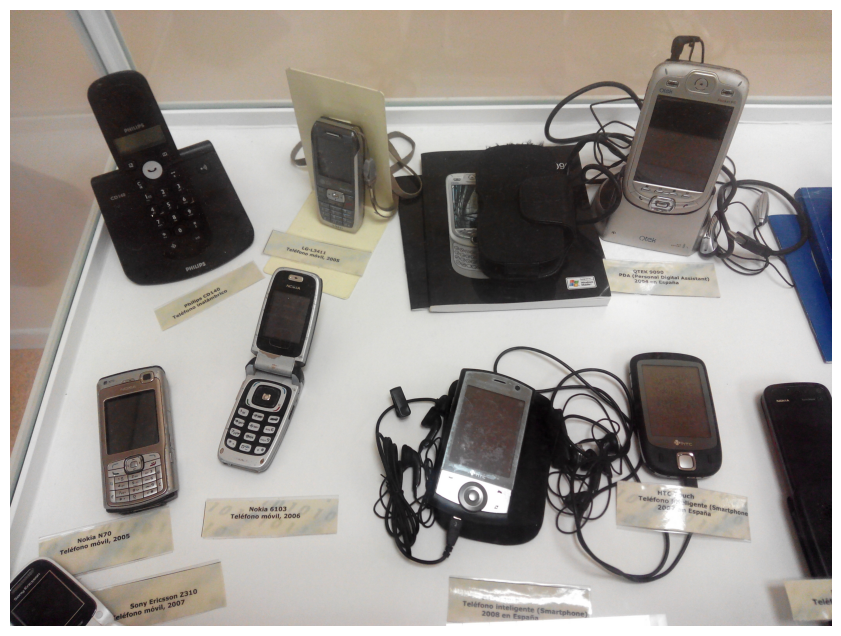

In [9]:
# Image de test libre de droit
image_url = "http://upload.wikimedia.org/wikipedia/commons/0/0d/Biblioteca_Maim%C3%B3nides%2C_Campus_Universitario_de_Rabanales_007.jpg"

image_np = load_image_into_numpy_array(image_url)

plt.figure(figsize=(12, 8))
plt.imshow(image_np[0])
plt.axis('off')
plt.show()

In [11]:
# Exécution de l'inférence
# Le modèle SSD MobileNet v2 requiert une entrée au format tf.uint8 (et non tf.float32)
converted_image = tf.cast(image_np, tf.uint8)
results = detector(converted_image)

# Extraction des résultats au format numpy
result = {key: value.numpy() for key, value in results.items()}

print("Clés disponibles dans les résultats :", list(result.keys()))
print(f"Nombre d'objets détectés : {len(result['detection_scores'][0])}")

Clés disponibles dans les résultats : ['detection_boxes', 'detection_multiclass_scores', 'raw_detection_scores', 'detection_classes', 'num_detections', 'detection_anchor_indices', 'raw_detection_boxes', 'detection_scores']
Nombre d'objets détectés : 100


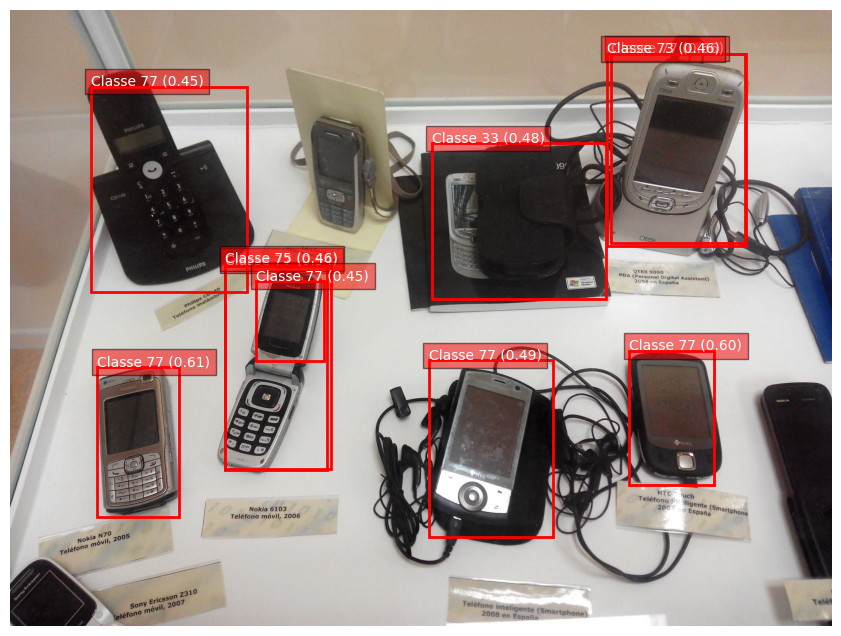

In [12]:
# Visualisation simple et propre sans dépendance externe complexe
image_to_plot = image_np[0].copy()
h, w, _ = image_to_plot.shape

boxes = result['detection_boxes'][0]
scores = result['detection_scores'][0]
classes = result['detection_classes'][0].astype(int)

plt.figure(figsize=(12, 8))
plt.imshow(image_to_plot)
ax = plt.gca()

# On trace les boîtes avec un score > 0.4
for box, score, cls in zip(boxes, scores, classes):
    if score > 0.4:
        ymin, xmin, ymax, xmax = box
        left, right, top, bottom = xmin * w, xmax * w, ymin * h, ymax * h

        rect = plt.Rectangle((left, top), right - left, bottom - top,
                             fill=False, edgecolor='red', linewidth=2)
        ax.add_patch(rect)
        ax.text(left, top - 5, f'Classe {cls} ({score:.2f})',
                bbox=dict(facecolor='red', alpha=0.5), color='white', fontsize=10)

plt.axis('off')
plt.show()